# 03 · Indicadores RFM
**Pregunta:** ¿cómo representar cada historial de compras en una fila?

Recencia mide días desde la última compra; frecuencia cuenta facturas distintas; valor monetario
suma gasto bruto. Los tres indicadores usan exactamente la misma ventana y fecha de corte.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "config/settings.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Abre el notebook dentro del repositorio.")
    ROOT = ROOT.parent
config = yaml.safe_load((ROOT / "config/settings.yaml").read_text(encoding="utf-8"))
REPORTS = ROOT / "reports"

In [2]:
from customer_segmentation.features import FEATURES, build_rfm, period

transactions = pd.read_parquet(ROOT / "data/processed/transactions.parquet")
rfm = build_rfm(transactions, config["observation_start"], config["cutoff"])
display(rfm.head())
assert rfm.customer_id.is_unique
assert rfm.last_purchase.lt(pd.Timestamp(config["cutoff"])).all()
assert rfm.frequency.ge(1).all()
assert rfm.recency.ge(1).all()
assert rfm.monetary.gt(0).all()
display(rfm[FEATURES].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2))

,customer_id,last_purchase,frequency,monetary,recency,average_order,cancelled_amount,net_amount,country
0,12346,2011-01-18 10:01:00,1,77183.60,226,77183.600,77189.1,-5.50,United Kingdom
1,12347,2011-08-02 08:48:00,6,3402.39,30,567.065,0.0,3402.39,Iceland
2,12348,2011-04-05 10:47:00,4,1709.40,149,427.350,0.0,1709.40,Finland
3,12349,2010-10-28 08:23:00,1,1402.62,308,1402.620,0.0,1402.62,Italy
4,12350,2011-02-02 16:01:00,1,334.40,211,334.400,0.0,334.40,Norway


,recency,frequency,monetary
count,4335.00,4335.00,4335.00
mean,144.49,4.11,1910.00
std,115.05,7.36,7653.34
min,1.00,1.00,2.90
25%,38.00,1.00,304.14
50%,112.00,2.00,645.65
75%,270.00,4.00,1559.45
95%,335.00,13.00,5885.21
99%,357.66,28.00,16767.21
max,365.00,186.00,268575.55


## Trazar un cliente hasta sus compras
El ejemplo se toma de los datos reales. Varias líneas de producto pueden pertenecer a una misma
factura, por lo que contar filas como frecuencia sobreestimaría los pedidos.

In [3]:
customer = rfm.iloc[0]
observed = period(transactions, config["observation_start"], config["cutoff"])
lines = observed.loc[observed.customer_id.eq(customer.customer_id)]
purchases = lines.loc[lines.status.eq("purchase")]
display(lines[["invoice", "date", "quantity", "price", "amount", "status"]].head(12))
display(customer.to_frame("Indicador"))
assert purchases.invoice.nunique() == customer.frequency
assert np.isclose(purchases.amount.sum(), customer.monetary)

,invoice,date,quantity,price,amount,status
294507,C525099,2010-10-04 09:54:00,-1,1.00,-1.0,cancellation
295906,C525274,2010-10-04 16:33:00,-1,4.50,-4.5,cancellation
440815,541431,2011-01-18 10:01:00,74215,1.04,77183.6,purchase
440820,C541433,2011-01-18 10:17:00,-74215,1.04,-77183.6,cancellation


,Indicador
customer_id,12346
last_purchase,2011-01-18 10:01:00
frequency,1
monetary,77183.6
recency,226
average_order,77183.6
cancelled_amount,77189.1
net_amount,-5.5
country,United Kingdom


## Escalas y asimetría
El gasto y la frecuencia tienen colas largas. La transformación logarítmica reduce esa asimetría;
el escalado posterior evita que las libras dominen a días y pedidos solo por su magnitud.
Las cifras originales se conservan para explicar los segmentos.

Clientes con saldo neto observado negativo: 15
El saldo puede incluir cancelaciones de compras anteriores a la ventana.


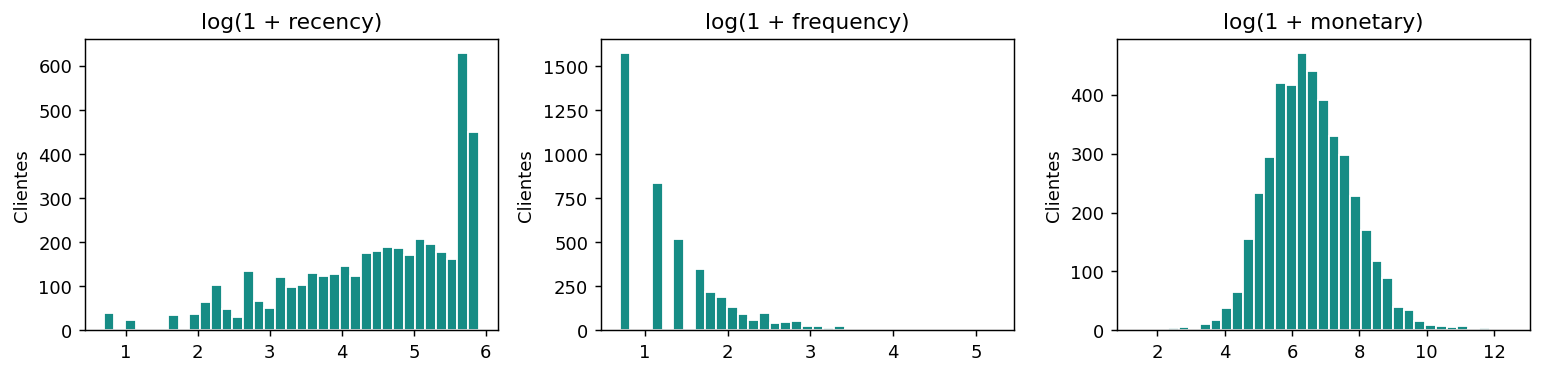

In [4]:
import io

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, feature in zip(axes, FEATURES):
    ax.hist(np.log1p(rfm[feature]), bins=35, color="#168C85", edgecolor="white")
    ax.set(title=f"log(1 + {feature})", ylabel="Clientes")
plt.tight_layout()

buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
display(Image(data=buffer.getvalue()))
plt.close(fig)
print(f"Clientes con saldo neto observado negativo: {rfm.net_amount.lt(0).sum()}")
print("El saldo puede incluir cancelaciones de compras anteriores a la ventana.")

## Decisión
El modelo recibe solamente recencia, frecuencia y gasto bruto. País, ticket y cancelaciones
sirven para describir, sin formar parte de la distancia entre clientes. Un comprador reciente
puede tener poca frecuencia porque tuvo menos tiempo para acumular pedidos; no se ajusta por
antigüedad de relación en esta versión.

[Continuar: evaluación del agrupamiento](04_clustering_evaluation.ipynb)